# 05 — ReMedFiLM predictions and semantic segmentation

Qualitative evidence from the saved VAL808 masks. Selection is deterministic: worst, median and best paired Δ Dice per domain — not cherry-picked.

**Evidence base**

- `reports/tables/phase27_val808_predictions.csv`
- `reports/predictions/phase21_*/val/<DOMAIN>/*.npz` (evaluation GT)
- `reports/figures/phase27_preservation/masks/*_{global,final}.png`

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 5.1 Selection rule

Within each domain the 808 samples are sorted by paired Δ Dice and three are
taken: the **worst**, the **median** and the **best**. The rule is fixed in code
and applied identically to every domain, so the gallery cannot be curated.

In [3]:
ps = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_PER_SAMPLE.csv")
for dom in ["ISIC", "BUSI", "KVASIR", "KUB"]:
    d = ps[ps.domain == dom].sort_values("delta_dice")
    picks = [d.iloc[0], d.iloc[len(d) // 2], d.iloc[-1]]
    print(f"{dom}: n={len(d)}")
    for tag, r in zip(("worst", "median", "best"), picks):
        print(f"   {tag:7s} {r.sample_id[:16]}  Δ={r.delta_dice:+.4f}  "
              f"{r.global_dice:.4f} -> {r.final_dice:.4f}  [{r.branch}]")

ISIC: n=357
   worst   e3a6813878b2407c  Δ=-0.0448  0.8446 -> 0.7997  [EXECUTE_THEN_ACCEPT]
   median  785d971b7375cc74  Δ=+0.0000  0.9335 -> 0.9335  [SKIP_GLOBAL]
   best    e49371af49edbb17  Δ=+0.0710  0.7507 -> 0.8217  [EXECUTE_THEN_ACCEPT]
BUSI: n=84
   worst   07451d37507d75a0  Δ=+0.0000  0.9109 -> 0.9109  [SKIP_GLOBAL]
   median  87e1131131f6dab9  Δ=+0.0000  0.8763 -> 0.8763  [SKIP_GLOBAL]
   best    7ac949e8e5e91a9a  Δ=+0.0077  0.8662 -> 0.8738  [EXECUTE_THEN_ACCEPT]
KVASIR: n=87
   worst   95925e9e2b42fd03  Δ=-0.0656  0.5341 -> 0.4684  [EXECUTE_THEN_ACCEPT]
   median  7b5ebd7204a3ab0a  Δ=+0.0000  0.8450 -> 0.8450  [SKIP_GLOBAL]
   best    71f1d13faf98f2d6  Δ=+0.0955  0.3712 -> 0.4667  [EXECUTE_THEN_ACCEPT]
KUB: n=280
   worst   fd8f2744680aa3a8  Δ=-0.0674  0.8775 -> 0.8101  [EXECUTE_THEN_ACCEPT]
   median  e6db42e46d012311  Δ=+0.0000  0.6761 -> 0.6761  [SKIP_GLOBAL]
   best    14d07b995aba3f25  Δ=+0.1258  0.6161 -> 0.7418  [EXECUTE_THEN_ACCEPT]


## 5.2 Panels — image · GT · backbone · FULL · TP/FP/FN

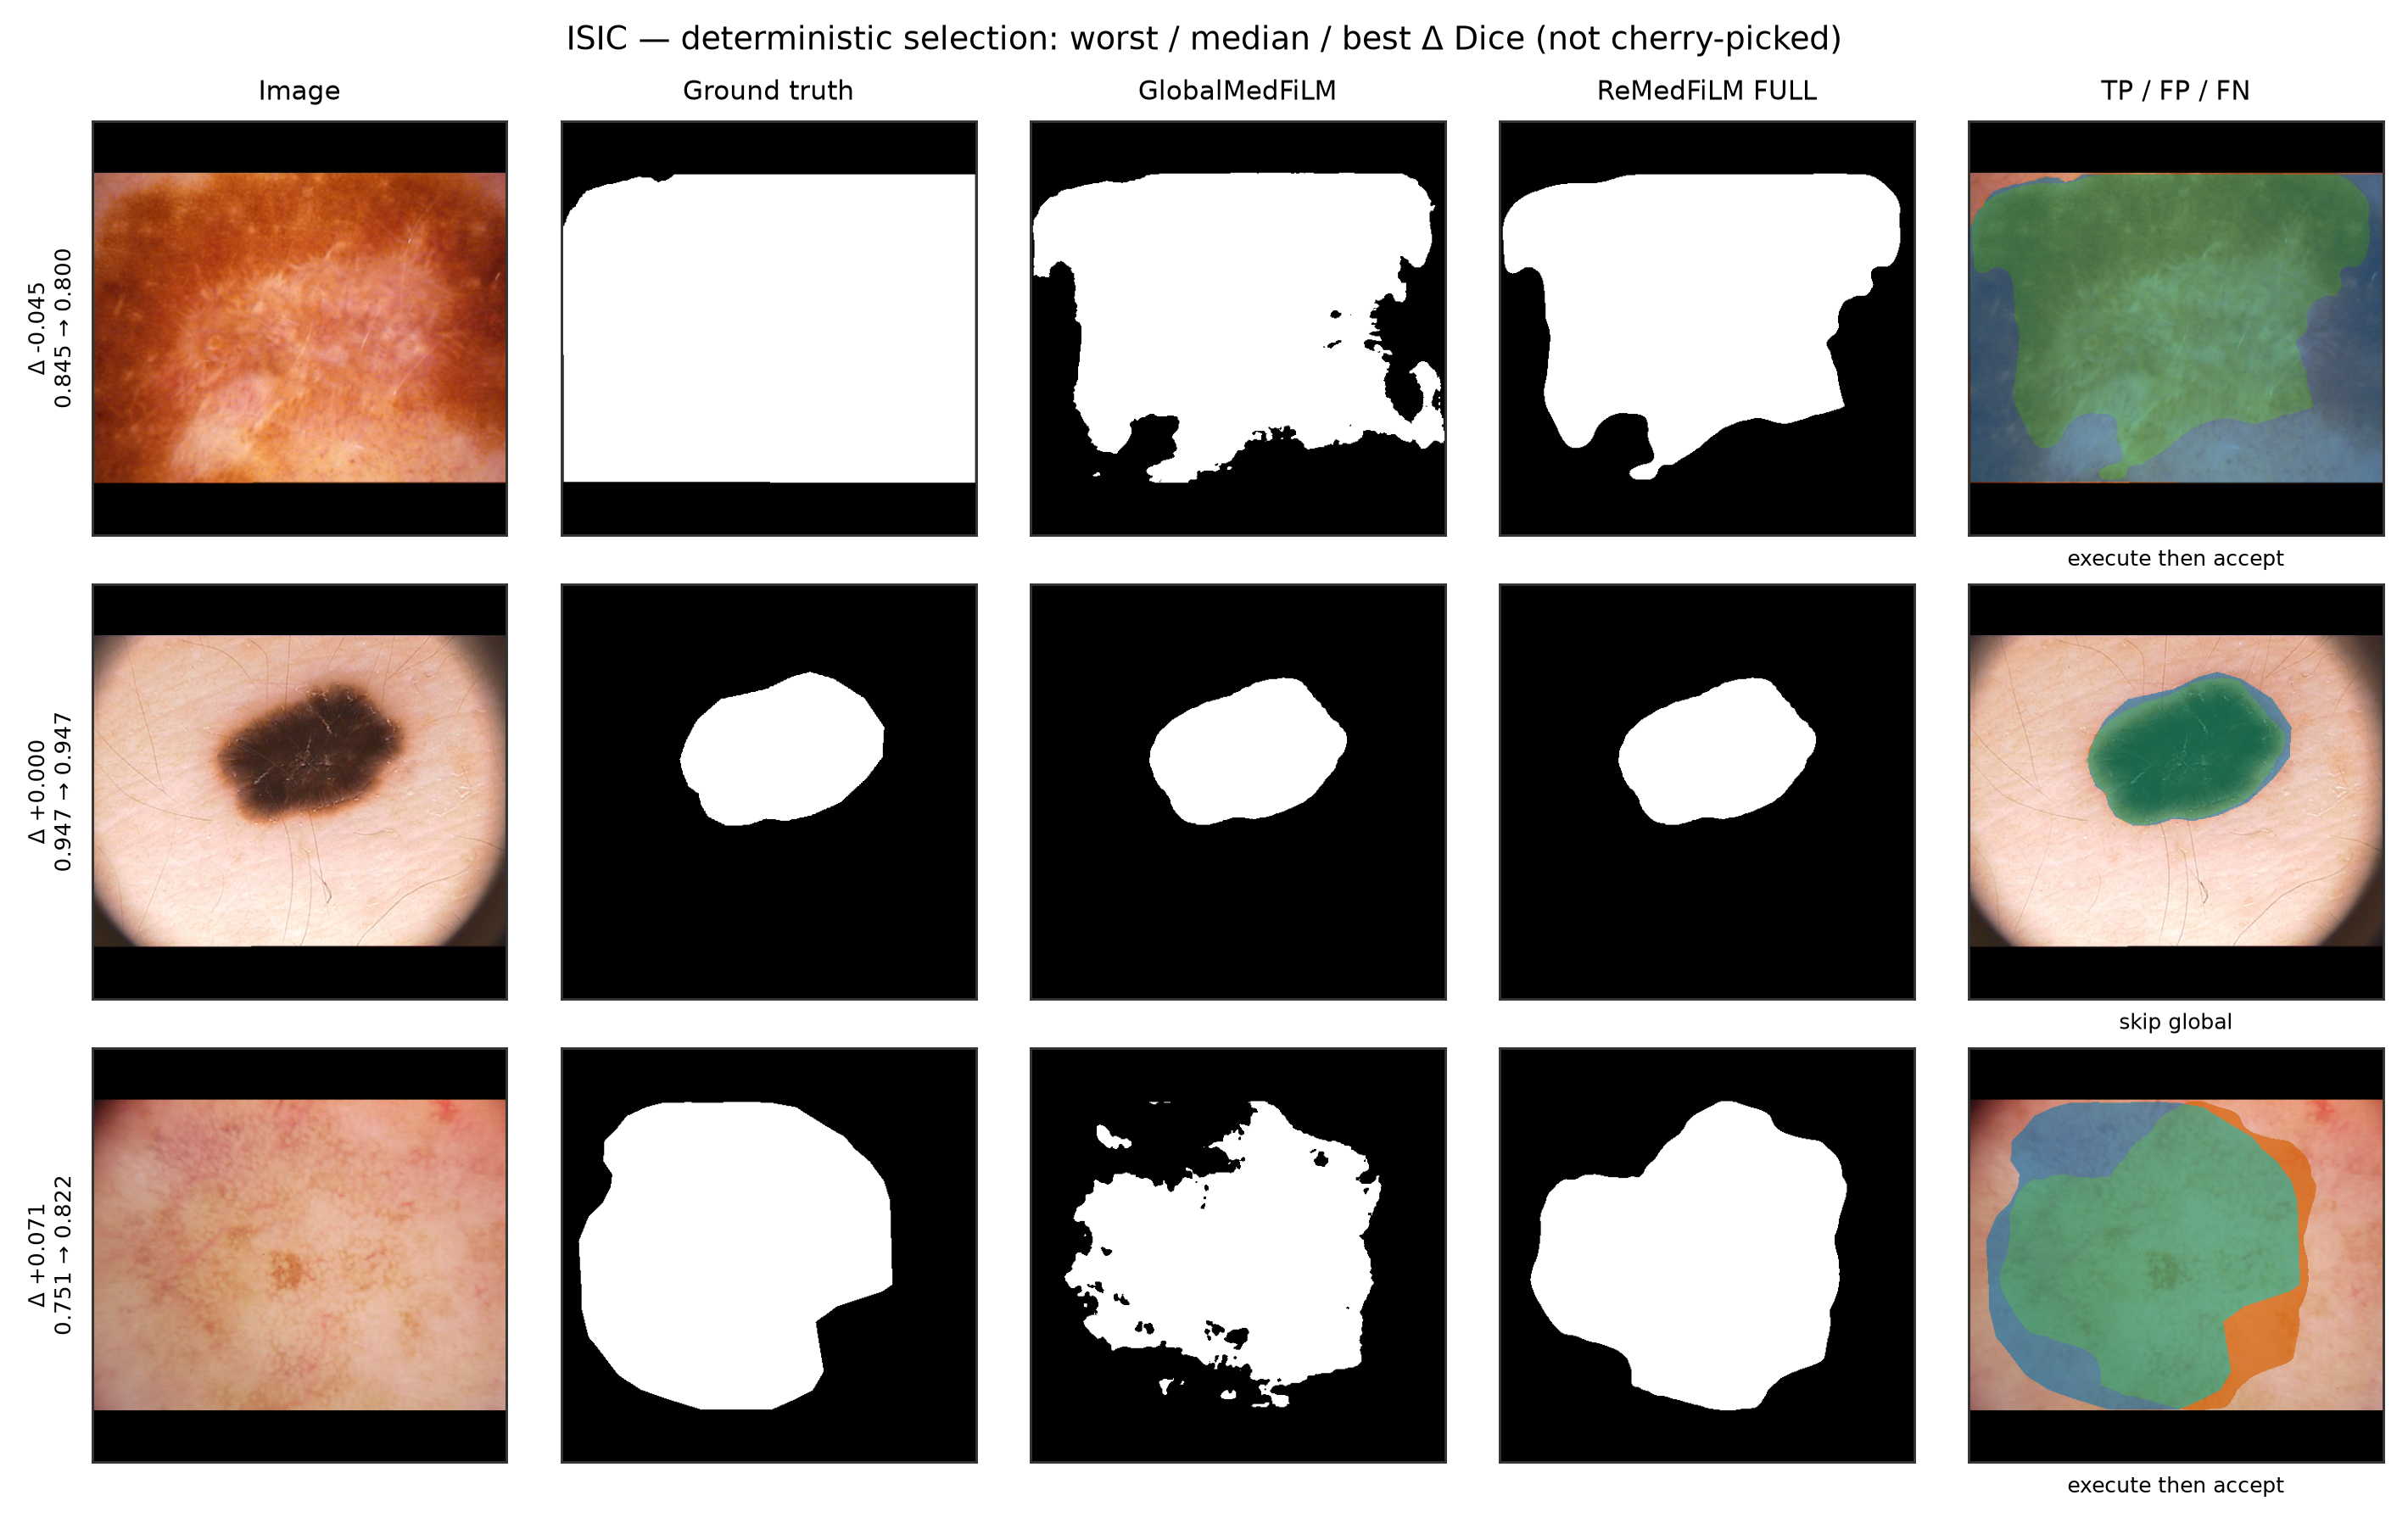

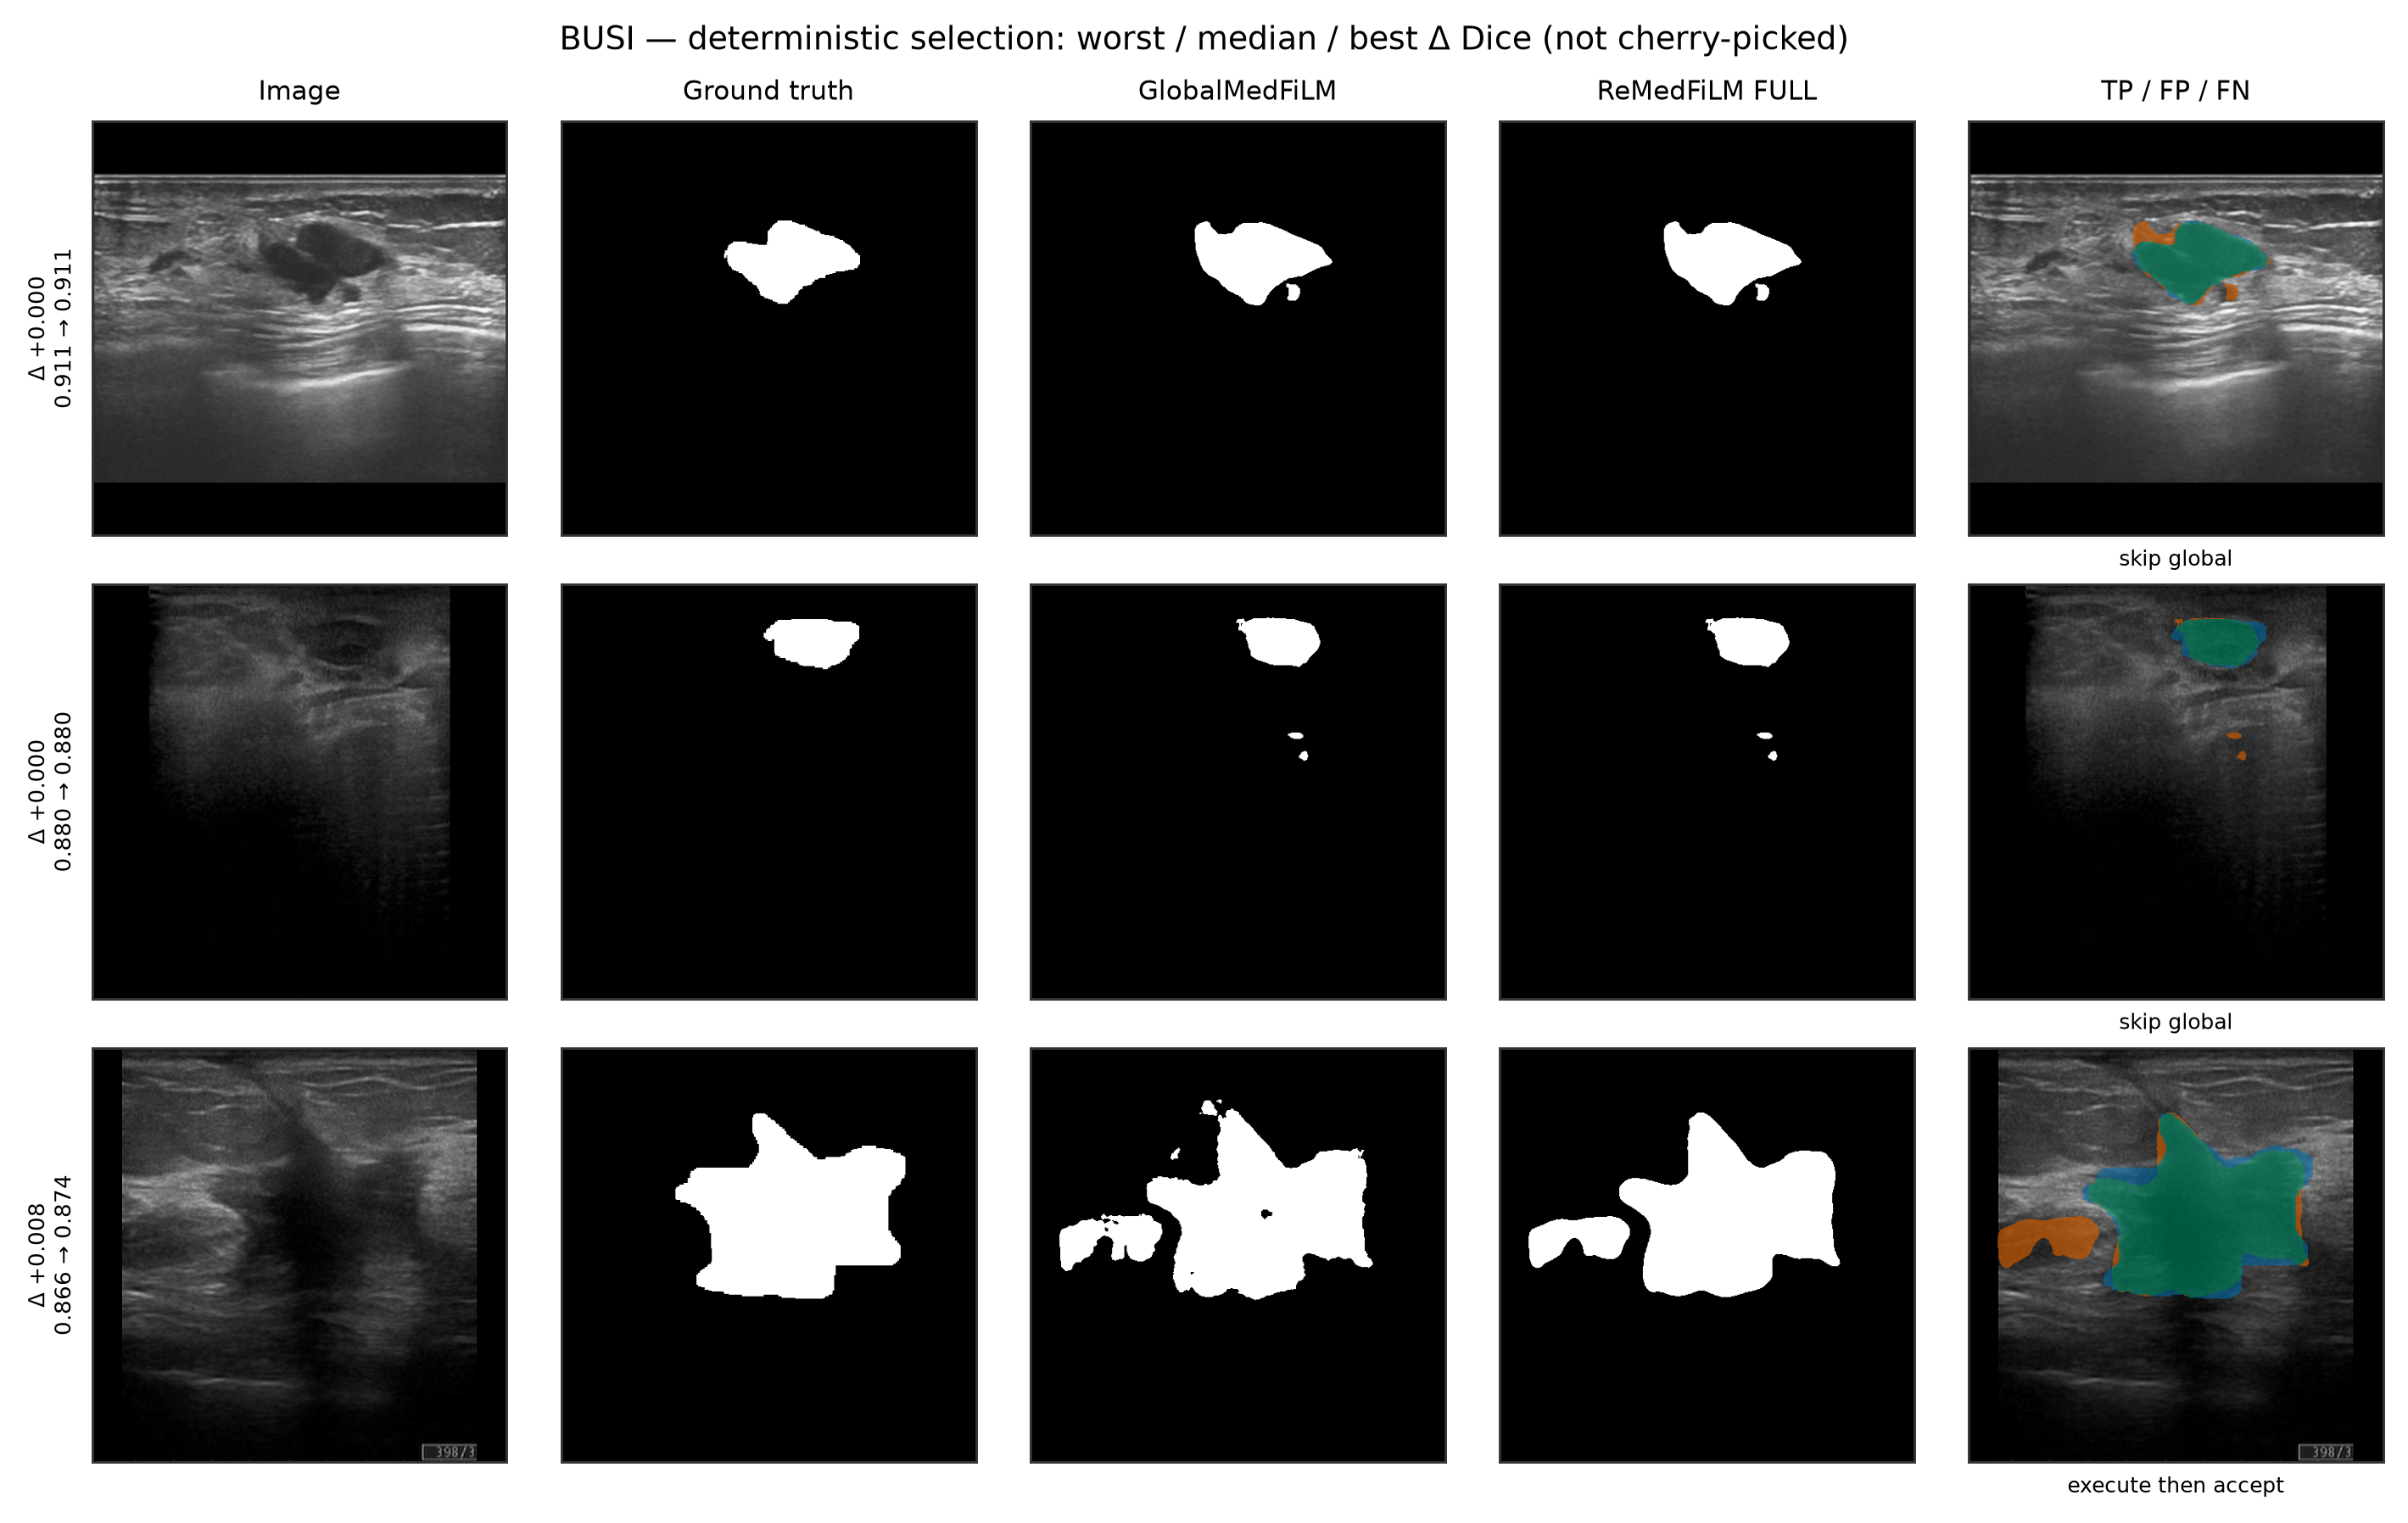

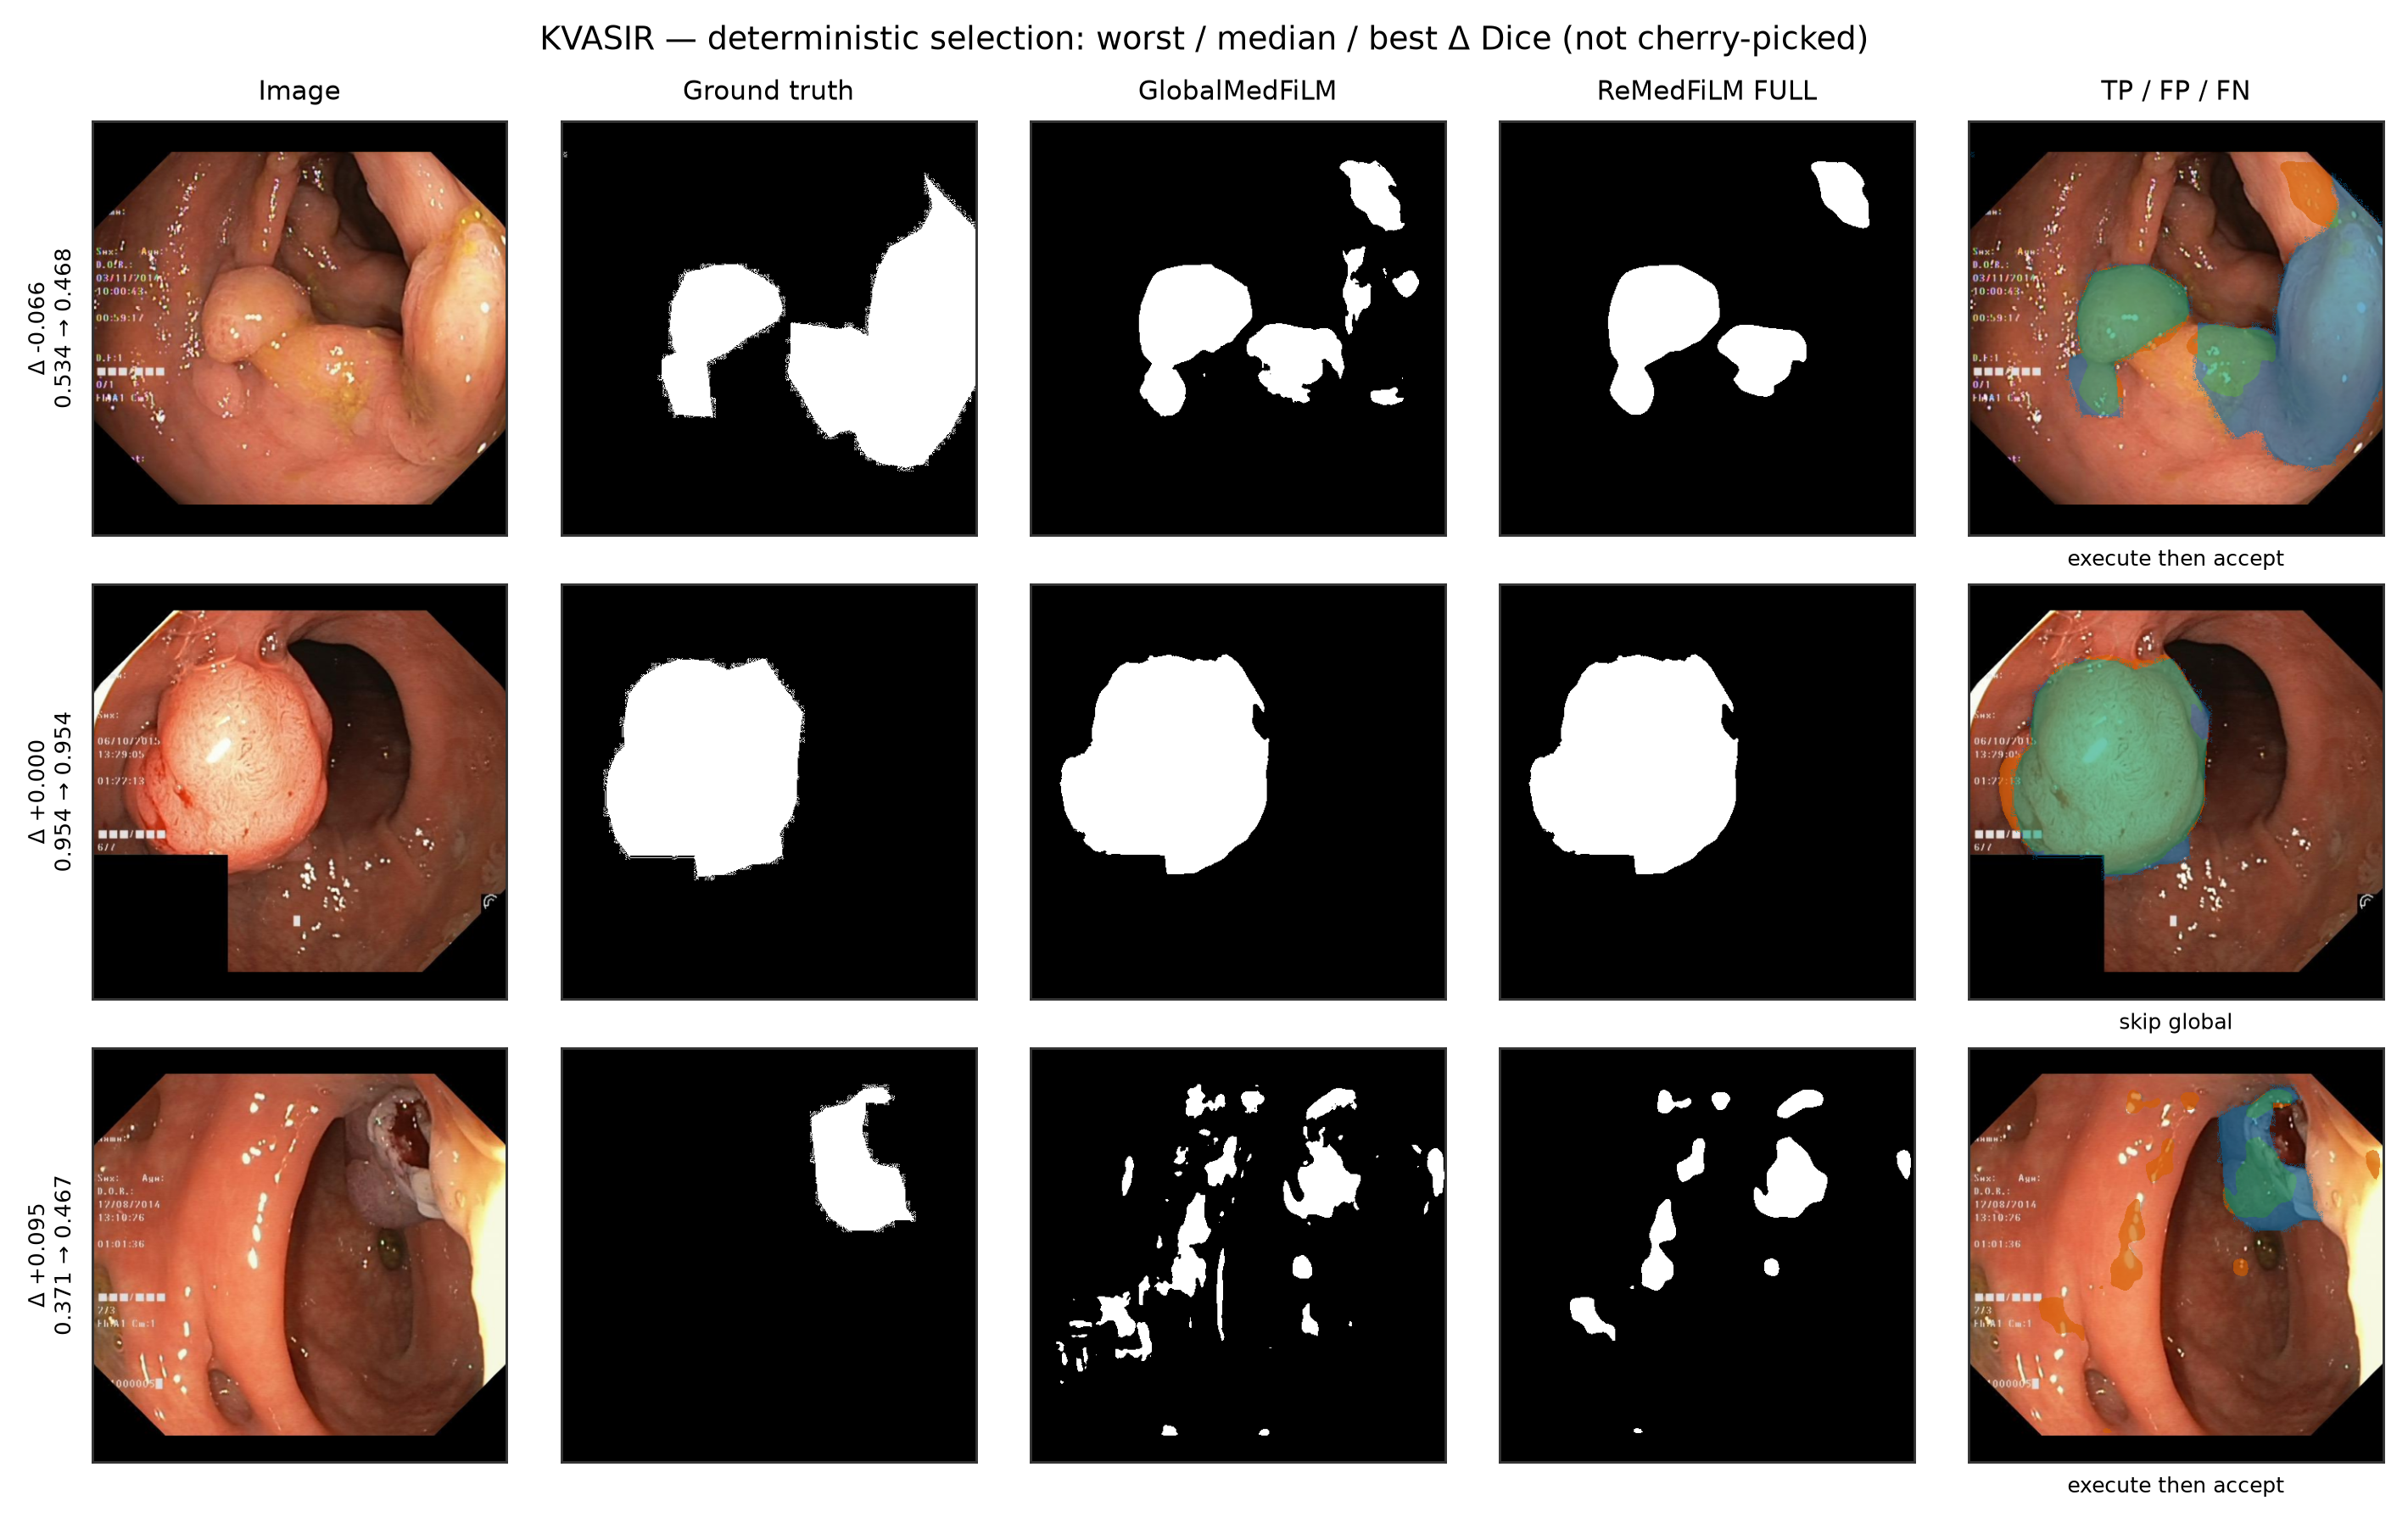

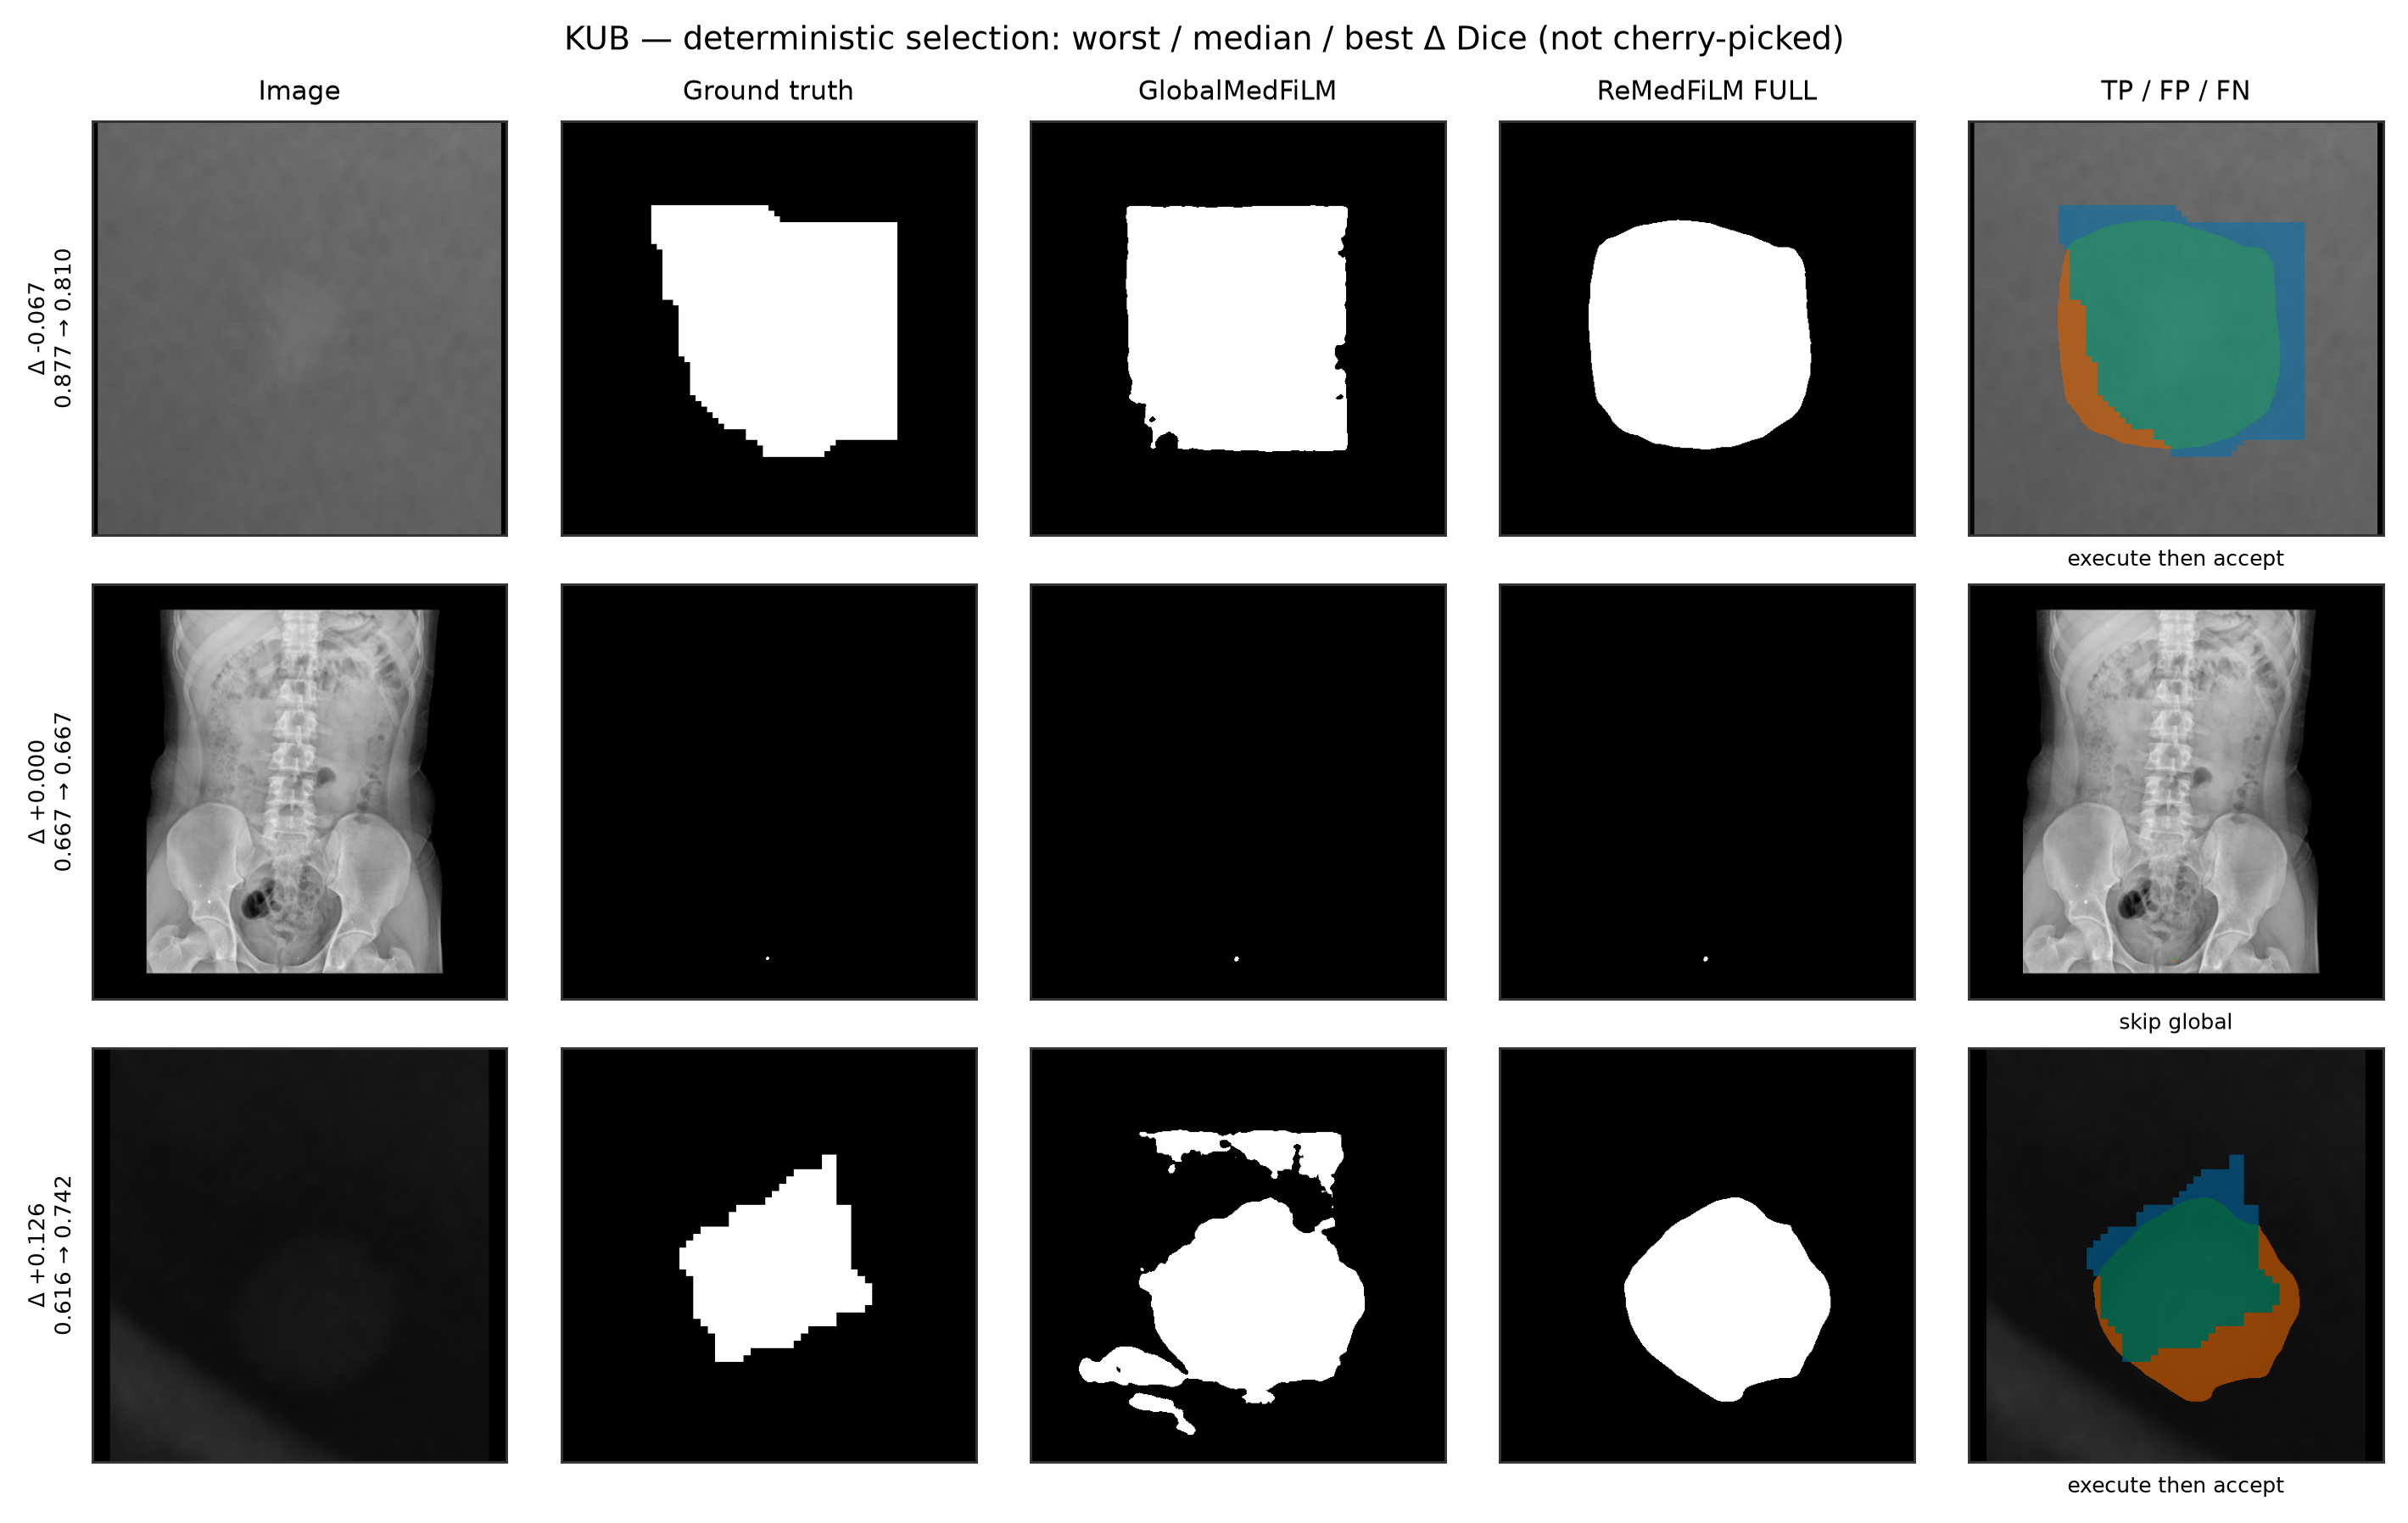

In [4]:
for dom in ["ISIC", "BUSI", "KVASIR", "KUB"]:
    fig("Semantic segmentation", f"SEG_{dom}_global_vs_full", width=900)

## 5.3 Genuine failure cases

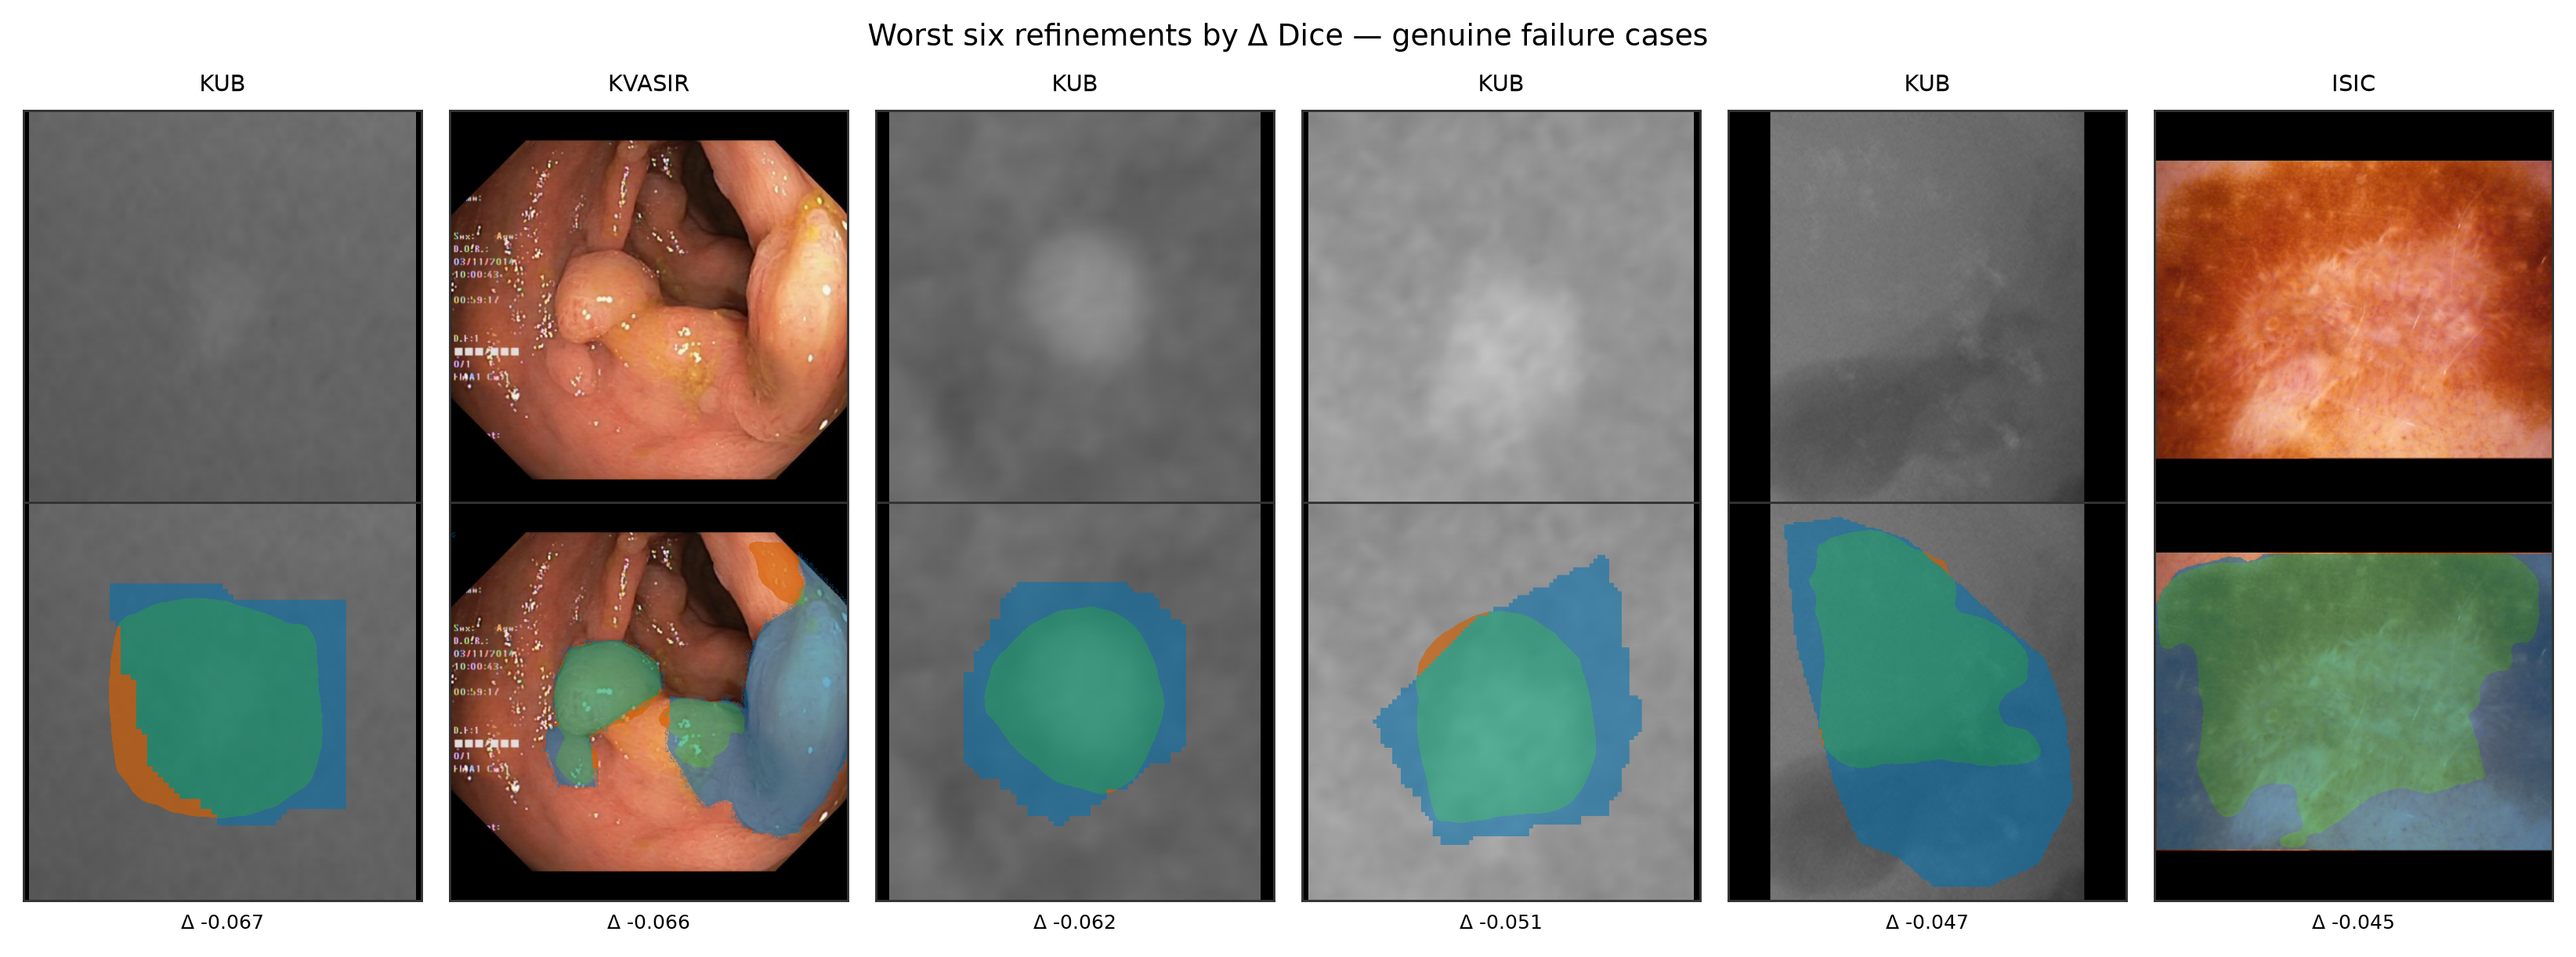

In [5]:
fig("Semantic segmentation", "SEG_failure_cases", width=920)

In [6]:
print("The six worst refinements by Δ Dice — accepted by the safety gate, so they")
print("are residual failures of the FULL system, not modelling artefacts.")
print()
print(ps.nsmallest(6, "delta_dice")[["sample_id", "domain", "global_dice",
                                     "final_dice", "delta_dice", "branch"]]
        .to_string(index=False))

The six worst refinements by Δ Dice — accepted by the safety gate, so they
are residual failures of the FULL system, not modelling artefacts.

                       sample_id domain  global_dice  final_dice  delta_dice              branch
fd8f2744680aa3a805f47a8151ef9761    KUB     0.877465    0.810078   -0.067387 EXECUTE_THEN_ACCEPT
95925e9e2b42fd03f8ad7c6581ae5cd1 KVASIR     0.534087    0.468447   -0.065640 EXECUTE_THEN_ACCEPT
59fa90de5303dd9b221630fed9322bc1    KUB     0.794817    0.732750   -0.062067 EXECUTE_THEN_ACCEPT
142bca47012895bafb72eaea84a586cb    KUB     0.799548    0.748839   -0.050709 EXECUTE_THEN_ACCEPT
fc65eaa53e1756122974223b22e35f07    KUB     0.743722    0.696281   -0.047441 EXECUTE_THEN_ACCEPT
e3a6813878b2407c0c8c2e534de8d40a   ISIC     0.844561    0.799714   -0.044847 EXECUTE_THEN_ACCEPT


## 5.4 KUB unit-of-analysis disclosure

KUB contributes both full-field radiographs and ROI instance patches. The panels
above mark which is which; they are never treated as interchangeable image units.

In [7]:
print("KUB rows in VAL808:", int((ps.domain == 'KUB').sum()))
print("KUB foreground area (median % of field):",
      round(float((ps[ps.domain == 'KUB'].gt_fg / (512 * 512) * 100).median()), 4))
print("ISIC foreground area (median % of field):",
      round(float((ps[ps.domain == 'ISIC'].gt_fg / (512 * 512) * 100).median()), 4))
print()
print("KUB lesions are roughly an order of magnitude smaller; this is why KUB")
print("carries both the largest gain and the worst tail in every analysis.")

KUB rows in VAL808: 280
KUB foreground area (median % of field): 16.8989
ISIC foreground area (median % of field): 11.998

KUB lesions are roughly an order of magnitude smaller; this is why KUB
carries both the largest gain and the worst tail in every analysis.


In [8]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
